In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Execution tiers. cpu = giga-cycles per second, rtt = round-trip delay (s),
# bw_factor = link speed relative to the base bandwidth trace.
TIERS = {
    "device": {"cpu": 1.0,  "rtt": 0.0,  "bw_factor": None},  # CPU: Chen et al. 2015
    "edge":   {"cpu": 5.0,  "rtt": 0.01, "bw_factor": 1.5},   # all three: assumption
    "cloud":  {"cpu": 10.0, "rtt": 0.07, "bw_factor": 1.0},   # CPU: Chen et al.; RTT: Huang 2013
}

# Phone power draw in watts: Kumar & Lu 2010
P_COMPUTE = 0.9   # computing locally
P_IDLE = 0.3      # waiting for a remote result
P_TX = 1.3        # sending data

# Cost = latency + energy weight x energy + penalty if the deadline is missed
W_LAT, W_ENERGY, DEADLINE_PENALTY = 1.0, 0.5, 5.0

N_TASKS = 5000
BW_SCALE = 0.4        # makes the average network speed about 5.7 Mbps
DEADLINE_SCALE = 2.0  # deadlines of 1 to 8 seconds
K = 5                 # how many past steps the predictor looks at later

mean bandwidth: 5.67 Mbps | median: 5.77 Mbps


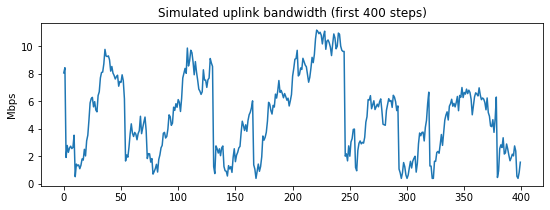

In [2]:
def make_bandwidth_trace(n, seed=0):
    """Mobile-like uplink bandwidth: drifts around a mean, with sudden drops."""
    r = np.random.default_rng(seed)
    out = np.empty(n)
    level = 20.0
    for t in range(n):
        level += r.normal(0, 1.5) + 0.05 * (20.0 - level)   # drift back toward the mean, plus noise
        level = np.clip(level, 1.0, 60.0)
        out[t] = level
        if r.random() < 0.03:                                # 3% chance of a sudden drop
            level = r.uniform(1.0, 4.0)
    return out

def make_tasks(n, seed=1):
    r = np.random.default_rng(seed)
    compute = r.lognormal(mean=0.8, sigma=0.8, size=n)   # giga-cycles of work
    data = r.lognormal(mean=0.2, sigma=1.0, size=n)      # MB to upload
    deadline = r.uniform(0.5, 4.0, size=n)               # seconds (before scaling)
    return compute, data, deadline

n = N_TASKS
bw = make_bandwidth_trace(n) * BW_SCALE
bw_prev = np.concatenate([[bw[0]], bw[:-1]])    # what the phone can see: last step's speed
compute, data, deadline = make_tasks(n)
deadline = deadline * DEADLINE_SCALE
train_end = K + int(0.7 * (n - K))              # first 70% = learning, last 30% = scoring

print(f"mean bandwidth: {bw.mean():.2f} Mbps | median: {np.median(bw):.2f} Mbps")

plt.figure(figsize=(9, 3))
plt.plot(bw[:400])
plt.title("Simulated uplink bandwidth (first 400 steps)")
plt.ylabel("Mbps")
plt.show()

In [3]:
def evaluate(tier, compute, data, deadline, bw_mbps):
    """Run one task on one tier. Returns (latency, energy, cost, missed)."""
    t = TIERS[tier]
    exec_time = compute / t["cpu"]
    if tier == "device":
        latency = exec_time
        energy = P_COMPUTE * exec_time
    else:
        tx_time = (data * 8.0) / (bw_mbps * t["bw_factor"])   # MB -> Mb, divide by Mbps
        latency = tx_time + t["rtt"] + exec_time
        energy = P_TX * tx_time + P_IDLE * (t["rtt"] + exec_time)
    missed = latency > deadline
    cost = W_LAT * latency + W_ENERGY * energy + (DEADLINE_PENALTY if missed else 0.0)
    return latency, energy, cost, missed

# Sanity check: 3 giga-cycles of work, 2 MB of data, 5 s deadline, 6 Mbps network
for name in TIERS:
    print(name, [round(float(v), 3) for v in evaluate(name, 3.0, 2.0, 5.0, 6.0)])

device [3.0, 2.7, 4.35, 0.0]
edge [2.388, 2.494, 3.635, 0.0]
cloud [3.037, 3.578, 4.825, 0.0]


In [4]:
BW_CUT = 2.0   # threshold rule: below this speed (Mbps), stay on the device

def threshold_policy(compute, data, deadline, bw_seen):
    """A simple hand-written rule."""
    if compute < 1.5:     return "device"   # small job, not worth sending
    if bw_seen < BW_CUT:  return "device"   # network looks bad
    if compute > 6:       return "cloud"    # big job, decent network
    return "edge"

def model_based(compute, data, deadline, bw_seen):
    """Knows the cost formula: tries every tier and picks the cheapest."""
    return min(TIERS, key=lambda name: evaluate(name, compute, data, deadline, bw_seen)[2])

# Three test tasks: (compute, data, deadline, bandwidth)
for args in [(3.0, 2.0, 5.0, 6.0), (3.0, 2.0, 5.0, 1.0), (8.0, 1.0, 5.0, 6.0)]:
    print(args, "threshold:", threshold_policy(*args), "| model_based:", model_based(*args))

(3.0, 2.0, 5.0, 6.0) threshold: edge | model_based: edge
(3.0, 2.0, 5.0, 1.0) threshold: device | model_based: device
(8.0, 1.0, 5.0, 6.0) threshold: cloud | model_based: cloud


In [5]:
tier_names = list(TIERS)

# Cut each feature into buckets. A "situation" is then just 4 small integers.
EDGES_BW_BASE = [1.2, 2.4, 4.8, 8.0]
EDGES = {"compute": [1.5, 3.0, 6.0], "data": [1.0, 3.0],
         "deadline": [2.0, 4.0, 6.0], "bw": list(EDGES_BW_BASE)}
SHAPE = (4, 3, 4, 5, 3)    # 4x3x4x5 situations, 3 tiers each

def context(i):
    return (np.digitize(compute[i],  EDGES["compute"]),
            np.digitize(data[i],     EDGES["data"]),
            np.digitize(deadline[i], EDGES["deadline"]),
            np.digitize(bw_prev[i],  EDGES["bw"]))

def train_bandit(passes=3, eps_start=0.3, eps_end=0.02, seed=0):
    r = np.random.default_rng(seed)
    Q = np.zeros(SHAPE)    # average cost seen so far, per situation and tier
    N = np.zeros(SHAPE)    # how many times each was tried
    step, total = 0, passes * train_end
    for _ in range(passes):
        for i in range(train_end):
            eps = eps_start + (eps_end - eps_start) * step / total   # explore less over time
            c = context(i)
            untried = np.where(N[c] == 0)[0]
            if r.random() < eps:
                a = r.integers(3)              # explore: random tier
            elif len(untried) > 0:
                a = untried[0]                 # try anything never tried in this situation
            else:
                a = int(np.argmin(Q[c]))       # exploit: tier with the lowest average cost
            cost = evaluate(tier_names[a], compute[i], data[i], deadline[i], bw[i])[2]
            N[c + (a,)] += 1
            Q[c + (a,)] += (cost - Q[c + (a,)]) / N[c + (a,)]        # running average
            step += 1
    return Q

def bandit_choice(Q, i):
    return tier_names[int(np.argmin(Q[context(i)]))]

# Test: train once, then see which tiers it picks on tasks it never trained on
Q = train_bandit(passes=3, seed=0)
print("Q shape:", Q.shape)
picks = [bandit_choice(Q, i) for i in range(train_end, n)]
print({t: picks.count(t) for t in ["device", "edge", "cloud"]})

Q shape: (4, 3, 4, 5, 3)
{'device': 684, 'edge': 577, 'cloud': 238}


In [6]:
def score(choice_fn, lo, hi):
    """Average latency, energy, cost and miss rate over tasks lo..hi."""
    rows = [evaluate(choice_fn(i), compute[i], data[i], deadline[i], bw[i]) for i in range(lo, hi)]
    lat, eng, cost, miss = np.array(rows, dtype=float).mean(axis=0)
    return lat, eng, cost, miss * 100

out = {}
for label, tier in [("always-local", "device"), ("always-edge", "edge"), ("always-cloud", "cloud")]:
    out[label] = score(lambda i, t=tier: t, train_end, n)

out["threshold"]   = score(lambda i: threshold_policy(compute[i], data[i], deadline[i], bw_prev[i]), train_end, n)
out["model-based"] = score(lambda i: model_based(compute[i], data[i], deadline[i], bw_prev[i]), train_end, n)
out["oracle"]      = score(lambda i: model_based(compute[i], data[i], deadline[i], bw[i]), train_end, n)

# The bandit is random, so train it with 5 different seeds and average
bandit_runs = []
for seed in range(5):
    Q = train_bandit(passes=3, seed=seed)
    bandit_runs.append(score(lambda i: bandit_choice(Q, i), train_end, n))
bandit_runs = np.array(bandit_runs)
out["bandit (avg of 5)"] = tuple(bandit_runs.mean(axis=0))

print(f"{'policy':<20}{'lat':>8}{'energy':>8}{'cost':>8}{'miss %':>8}")
for name, (l, e, c, m) in out.items():
    print(f"{name:<20}{l:>8.3f}{e:>8.3f}{c:>8.3f}{m:>8.1f}")
print("bandit cost per seed:", np.round(bandit_runs[:, 2], 3))

policy                   lat  energy    cost  miss %
always-local           2.974   2.677   5.620    26.2
always-edge            3.185   3.535   6.143    23.8
always-cloud           4.237   5.141   8.412    32.1
threshold              2.454   2.579   4.578    16.7
model-based            1.709   1.549   3.037    11.1
oracle                 1.665   1.487   2.932    10.5
bandit (avg of 5)      1.870   1.723   3.363    12.6
bandit cost per seed: [3.387 3.299 3.372 3.415 3.343]


 noise  last-bw predicted  oracle  gain %
  0.05    3.037     2.934   2.932     3.4
  0.15    3.037     2.948   2.932     2.9
   0.3    3.037     2.965   2.932     2.4
   0.6    3.037     3.009   2.932     0.9
   1.0    3.037     3.017   2.932     0.7
   2.0    3.037     3.025   2.932     0.4


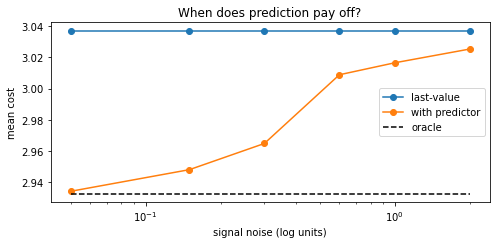

In [7]:
def predictor_experiment(sigma, seed=7):
    """sigma = how noisy the signal-strength reading is."""
    r = np.random.default_rng(seed)
    logbw = np.log(bw)
    # Simulated signal reading: it reflects the NEXT bandwidth, plus noise
    rssi = np.empty(n)
    rssi[:-1] = logbw[1:] + r.normal(0, sigma, n - 1)
    rssi[-1] = logbw[-1]

    # Features: last K speeds + last K signal readings + a constant. Target: the next speed.
    X = np.array([np.concatenate([logbw[i-K:i], rssi[i-K:i], [1.0]]) for i in range(K, n)])
    y = logbw[K:n]
    split = int(0.7 * len(y))
    w, *_ = np.linalg.lstsq(X[:split], y[:split], rcond=None)      # linear regression
    pred = np.clip(np.exp(X @ w), bw.min(), bw.max())

    seen_last = np.concatenate([[bw[0]] * K, bw[K-1:n-1]])         # just the previous speed
    seen_pred = np.concatenate([[bw[0]] * K, pred])                # the model's forecast
    start = K + split

    def mean_cost(seen):
        return np.mean([evaluate(model_based(compute[i], data[i], deadline[i], seen[i]),
                                 compute[i], data[i], deadline[i], bw[i])[2] for i in range(start, n)])
    return mean_cost(seen_last), mean_cost(seen_pred), mean_cost(bw)

sigmas = [0.05, 0.15, 0.3, 0.6, 1.0, 2.0]
pres = np.array([predictor_experiment(s) for s in sigmas])

print(f"{'noise':>6}{'last-bw':>9}{'predicted':>10}{'oracle':>8}{'gain %':>8}")
for s, (cl, cp, co) in zip(sigmas, pres):
    print(f"{s:>6}{cl:>9.3f}{cp:>10.3f}{co:>8.3f}{(cl - cp) / cl * 100:>8.1f}")

plt.figure(figsize=(7, 3.5))
plt.plot(sigmas, pres[:, 0], "o-", label="last-value")
plt.plot(sigmas, pres[:, 1], "o-", label="with predictor")
plt.plot(sigmas, pres[:, 2], "k--", label="oracle")
plt.xscale("log"); plt.xlabel("signal noise (log units)"); plt.ylabel("mean cost")
plt.title("When does prediction pay off?"); plt.legend()
plt.tight_layout(); plt.show()

In [8]:
BASE_EDGES_BW = EDGES_BW_BASE

def run_setting(bw_scale=0.4, w_energy=0.5, edge_cpu=5.0, seeds=5):
    """Rerun the comparison with one setting changed, then restore the defaults."""
    global bw, bw_prev, W_ENERGY, BW_CUT
    try:
        k = bw_scale / 0.4                       # network-based settings scale with the trace
        bw = make_bandwidth_trace(n) * bw_scale
        bw_prev = np.concatenate([[bw[0]], bw[:-1]])
        EDGES["bw"] = [e * k for e in BASE_EDGES_BW]
        BW_CUT = 2.0 * k
        W_ENERGY = w_energy
        TIERS["edge"]["cpu"] = edge_cpu

        thr = score(lambda i: threshold_policy(compute[i], data[i], deadline[i], bw_prev[i]), train_end, n)[2]
        ban = np.mean([score(lambda i, Q=train_bandit(passes=3, seed=s): bandit_choice(Q, i), train_end, n)[2]
                       for s in range(seeds)])
        mb  = score(lambda i: model_based(compute[i], data[i], deadline[i], bw_prev[i]), train_end, n)[2]
        orc = score(lambda i: model_based(compute[i], data[i], deadline[i], bw[i]), train_end, n)[2]
        return dict(thr=thr, ban=ban, mb=mb, orc=orc, gain=(thr - ban) / thr * 100)
    finally:                                     # always put the base settings back
        bw = make_bandwidth_trace(n) * BW_SCALE
        bw_prev = np.concatenate([[bw[0]], bw[:-1]])
        EDGES["bw"] = list(BASE_EDGES_BW)
        BW_CUT, W_ENERGY = 2.0, 0.5
        TIERS["edge"]["cpu"] = 5.0

groups = {
    "Network speed":  [("0.5x", dict(bw_scale=0.2)), ("1x (base)", dict(bw_scale=0.4)),
                       ("2x", dict(bw_scale=0.8)),   ("4x", dict(bw_scale=1.6))],
    "Energy weight":  [("0", dict(w_energy=0.0)), ("0.5 (base)", dict(w_energy=0.5)),
                       ("1", dict(w_energy=1.0)), ("2", dict(w_energy=2.0))],
    "Edge CPU speed": [("2.5 GHz", dict(edge_cpu=2.5)), ("5 GHz (base)", dict(edge_cpu=5.0)),
                       ("10 GHz", dict(edge_cpu=10.0))],
}
results = {g: [(lab, run_setting(**kw)) for lab, kw in items] for g, items in groups.items()}

print(f"{'setting':<30}{'threshold':>10}{'bandit':>8}{'model':>8}{'oracle':>8}{'gain %':>8}")
for g, rows in results.items():
    for lab, r in rows:
        print(f"{g + ': ' + lab:<30}{r['thr']:>10.3f}{r['ban']:>8.3f}{r['mb']:>8.3f}{r['orc']:>8.3f}{r['gain']:>8.1f}")

setting                        threshold  bandit   model  oracle  gain %
Network speed: 0.5x                7.730   4.174   3.935   3.841    46.0
Network speed: 1x (base)           4.578   3.363   3.037   2.932    26.5
Network speed: 2x                  2.924   2.400   2.199   2.114    17.9
Network speed: 4x                  2.095   1.687   1.560   1.490    19.5
Energy weight: 0                   3.288   2.487   2.253   2.183    24.4
Energy weight: 0.5 (base)          4.578   3.363   3.037   2.932    26.5
Energy weight: 1                   5.868   4.194   3.785   3.674    28.5
Energy weight: 2                   8.447   5.826   5.314   5.152    31.0
Edge CPU speed: 2.5 GHz            5.196   3.592   3.313   3.198    30.9
Edge CPU speed: 5 GHz (base)       4.578   3.363   3.037   2.932    26.5
Edge CPU speed: 10 GHz             4.314   2.966   2.677   2.595    31.2


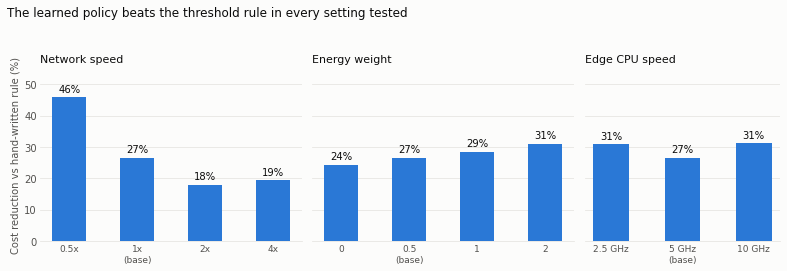

In [9]:
INK, INK2, GRID, SURF, BAR = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb", "#2a78d6"
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True,
                         gridspec_kw={"width_ratios": [4, 4, 3]}, facecolor=SURF)
for ax, (g, rows) in zip(axes, results.items()):
    labels = [lab for lab, _ in rows]
    gains = [r["gain"] for _, r in rows]
    xs = np.arange(len(rows))
    ax.set_facecolor(SURF)
    ax.bar(xs, gains, width=0.5, color=BAR, zorder=3)
    for x, v in zip(xs, gains):
        ax.text(x, v + 1.0, f"{v:.0f}%", ha="center", va="bottom", fontsize=10, color=INK)
    ax.set_xticks(xs)
    ax.set_xticklabels([l.replace(" (base)", "\n(base)") for l in labels], fontsize=9, color=INK2)
    ax.set_title(g, fontsize=11, color=INK, loc="left")
    ax.set_ylim(0, 55)
    ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(axis="y", colors=INK2, length=0)
    ax.tick_params(axis="x", length=0)
axes[0].set_ylabel("Cost reduction vs hand-written rule (%)", fontsize=10, color=INK2)
fig.suptitle("The learned policy beats the threshold rule in every setting tested",
             fontsize=12, color=INK, x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig("robustness.png", dpi=150, facecolor=SURF)
plt.show()

In [10]:
def run_world(env_seed, seeds=3):
    global bw, bw_prev, compute, data, deadline
    try:
        bw = make_bandwidth_trace(n, seed=100 + env_seed) * BW_SCALE
        bw_prev = np.concatenate([[bw[0]], bw[:-1]])
        compute, data, deadline = make_tasks(n, seed=200 + env_seed)
        deadline = deadline * DEADLINE_SCALE
        thr = score(lambda i: threshold_policy(compute[i], data[i], deadline[i], bw_prev[i]), train_end, n)[2]
        ban = np.mean([score(lambda i, Q=train_bandit(passes=3, seed=s): bandit_choice(Q, i), train_end, n)[2]
                       for s in range(seeds)])
        mb  = score(lambda i: model_based(compute[i], data[i], deadline[i], bw_prev[i]), train_end, n)[2]
        orc = score(lambda i: model_based(compute[i], data[i], deadline[i], bw[i]), train_end, n)[2]
        return thr, ban, mb, orc, (thr - ban) / thr * 100
    finally:                                     # restore the main world
        bw = make_bandwidth_trace(n) * BW_SCALE
        bw_prev = np.concatenate([[bw[0]], bw[:-1]])
        compute, data, deadline = make_tasks(n)
        deadline = deadline * DEADLINE_SCALE

worlds = [run_world(s) for s in range(10)]
print(f"{'world':>6}{'threshold':>10}{'bandit':>8}{'model':>8}{'oracle':>8}{'gain %':>8}")
for s, (t, b, m, o, g) in enumerate(worlds):
    print(f"{s:>6}{t:>10.3f}{b:>8.3f}{m:>8.3f}{o:>8.3f}{g:>8.1f}")
gains = np.array([w[4] for w in worlds])
print("gain: mean %.1f  min %.1f  max %.1f  std %.1f" % (gains.mean(), gains.min(), gains.max(), gains.std()))

 world threshold  bandit   model  oracle  gain %
     0     4.942   3.766   3.429   3.199    23.8
     1     5.750   4.148   3.832   3.683    27.9
     2     4.800   3.618   3.411   3.262    24.6
     3     4.592   3.443   3.206   3.136    25.0
     4     4.900   3.751   3.434   3.312    23.4
     5     4.497   3.505   3.303   3.189    22.1
     6     4.668   3.558   3.226   3.067    23.8
     7     4.425   3.477   3.260   3.064    21.4
     8     4.792   3.793   3.423   3.277    20.9
     9     4.298   3.439   3.214   3.060    20.0
gain: mean 23.3  min 20.0  max 27.9  std 2.2


## Conclusions and limits

**Results**
- A learned policy (contextual bandit) cut cost by 26.5% versus a hand-written threshold rule in the main run, and by 23.3% on average over 10 random draws of the network and tasks (range 20.0% to 27.9%). It never saw the cost formula.
- The gain held in all 11 settings tested (network speed, energy weight, edge CPU speed): 18% to 46%, largest when the network is slow.
- Predicting the network helped only a little: at most 3.4% with a clean simulated signal, and under 1% with a noisy one.

**Limits**
- This is a simulation. No real device or network was measured.
- The literature values date from 2010 to 2015.
- The edge-tier values, the deadlines and the signal-strength reading are our own assumptions.
- The threshold rule is simple and was not tuned for each setting. A tuned rule would narrow the gap.
- The bandit's settings were chosen once and not tuned.